# Прогнозирование температуры звезды с помощью нейронной сети

**Цель работы:** Обучить нейросеть определять температуру на поверхности обнаруженных звёзд.

В базе обсерватории есть характеристики уже изученных 240 звёзд:
* Относительная светимость L/Lo — светимость звезды относительно Солнца.
* Относительный радиус R/Ro — радиус звезды относительно радиуса Солнца.
* Абсолютная звёздная величина Mv — физическая величина, характеризующая блеск звезды.
* Звёздный цвет (white, red, blue, yellow, yellow-orange и др.) — цвет звезды, который определяют на основе спектрального анализа.
* Тип звезды: Коричневый карлик	- 0, Красный карлик - 1, Белый карлик - 2, Звёзды главной последовательности - 3, Сверхгигант - 4, Гипергигант - 5.
* Абсолютная температура T(K) — температура на поверхности звезды в Кельвинах.

**План работы**
1. Загрузка данных
2. Предобработка и анализ данных
3. Построение базовой нейронной сети
4. Улучшение нейронной сети
5. Выводы

## Загрузка данных

In [1]:
!pip install phik -q

In [2]:
# Импортируем необходимые библиотеки
import os
import pandas as pd
import random
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

from phik import phik_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import itertools

In [3]:
# Для воспроизводимости результатов
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.use_deterministic_algorithms(True)

In [4]:
# Загружаем исходные данные из файла
data_path = '6_class.csv'

if os.path.exists(data_path):
    df = pd.read_csv('6_class.csv')
else:
    print('Something is wrong')

In [5]:
# Первые строки датафрейма
df.head(5)

,Unnamed: 0,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color
0,0,3068,0.002400,0.1700,16.12,0,Red
1,1,3042,0.000500,0.1542,16.60,0,Red
2,2,2600,0.000300,0.1020,18.70,0,Red
3,3,2800,0.000200,0.1600,16.65,0,Red
4,4,1939,0.000138,0.1030,20.06,0,Red


In [6]:
# Общая информация
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              240 non-null    int64  
 1   Temperature (K)         240 non-null    int64  
 2   Luminosity(L/Lo)        240 non-null    float64
 3   Radius(R/Ro)            240 non-null    float64
 4   Absolute magnitude(Mv)  240 non-null    float64
 5   Star type               240 non-null    int64  
 6   Star color              240 non-null    object 
dtypes: float64(3), int64(3), object(1)
memory usage: 13.3+ KB


В датафрейме хранится информация о уже изученных звёздах: всего 240 строк и 7 столбцов. В первом столбце указан индекс строки, остальные столбцы хранят информацию о характеристиках звёзды. Типы данных корректны, пропусков нет.    

## Предобработка и анализ данных

### Предобработка данных

Можно удалить первый столбец из датафрейма, т.к. он не содержит полезной информации

In [7]:
df = df.drop('Unnamed: 0', axis=1)
df.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color
0,3068,0.002400,0.1700,16.12,0,Red
1,3042,0.000500,0.1542,16.60,0,Red
2,2600,0.000300,0.1020,18.70,0,Red
3,2800,0.000200,0.1600,16.65,0,Red
4,1939,0.000138,0.1030,20.06,0,Red


Исследуем данные на наличие пропусков, явных и неявных дубликатов

In [8]:
# Выводим количество пропусков в датафрейме
print(f'В датафрейме {df.isna().sum().sum()} пропусков')

В датафрейме 0 пропусков


In [9]:
# Выводим количество явных дубликатов в датафрейме
print(f'В датафрейме {df.duplicated().sum()} дубликатов')

В датафрейме 0 дубликатов


In [10]:
# Выводим уникальные значения столбца `Star color`
df['Star color'].unique()

array(['Red', 'Blue White', 'White', 'Yellowish White', 'Blue white',
       'Pale yellow orange', 'Blue', 'Blue-white', 'Whitish',
       'yellow-white', 'Orange', 'White-Yellow', 'white', 'Blue ',
       'yellowish', 'Yellowish', 'Orange-Red', 'Blue white ',
       'Blue-White'], dtype=object)

Из-за разных форматов записи возникают неявные дубликаты. Приведем записи к единообразию: переведем в нижний регистр, удалим пробелы в начале и конце, заменим пробелы в остальных случаях на дефис.

In [11]:
df['Star color'] = df['Star color'].str.lower().str.strip().str.replace(' ', '-')

In [12]:
df['Star color'] = df['Star color'].replace(['yellow-white'],'white-yellow')
df['Star color'].unique()

array(['red', 'blue-white', 'white', 'yellowish-white',
       'pale-yellow-orange', 'blue', 'whitish', 'white-yellow', 'orange',
       'yellowish', 'orange-red'], dtype=object)

Теперь в `Star color` есть 11 категорий цвета. Согласно основной (гарвардской) спектральной классификации звезд имеется 7 основных цветов: blue, blue-white, white, white-yellow, yellow, orange, red. Поэтому можно объединить похожие цвета, оставив только основные.

In [13]:
color_mapping = {
    'yellowish-white': 'white-yellow',
    'yellowish': 'yellow',
    'pale-yellow-orange': 'orange',
    'orange-red': 'orange',
    'whitish': 'white'
}

df['Star color'] = df['Star color'].replace(color_mapping)

In [14]:
# Выводим уникальные значения столбца  `Star color` после преобразований
df['Star color'].unique()

array(['red', 'blue-white', 'white', 'white-yellow', 'orange', 'blue',
       'yellow'], dtype=object)

В результате, количество категорий `Star color` уменьшилось до 7. При этом физический смысл сохранился, а статистическая значимость категорий возросла.

Избавились от неявных дубликатов, перейдем к исследовательскому анализу данных

### Исследовательский анализ данных

In [15]:
# Cтатистика для числовых столбцов
df.describe()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,40000.000000,849420.000000,1948.500000,20.060000,5.000000


Для всех количественных данных среднее значение отличается от медианы, изучим эти данные подробнее, построив графики.

In [16]:
# Функция для построения гистограммы и диаграммы размаха для количественных признаков
def hist_and_boxplot(x, df, bins):
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 2, 1) 
    sns.histplot(data=df, x=x, bins=bins, kde=True)
    plt.title('Гистограмма')
    plt.subplot(1, 2, 2) 
    df.boxplot(column=x)
    plt.title('Диаграмма размаха')
    plt.suptitle(x, fontsize=15)
    plt.show()

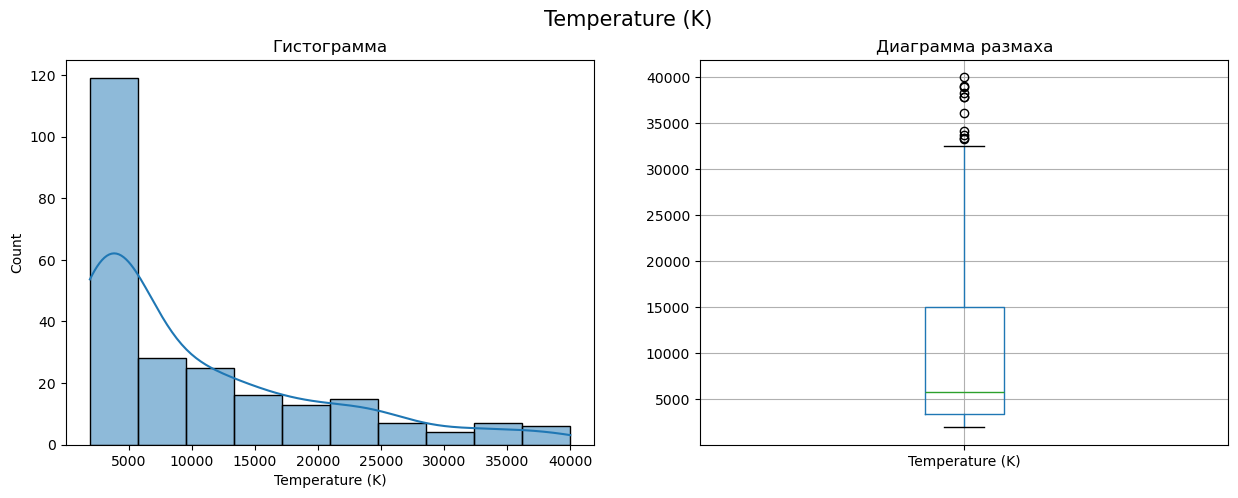

In [17]:
hist_and_boxplot('Temperature (K)', df, 10)

Температура поверхности звезд варьируется от 1939 до 40000 градусов Кельвина. На гистрограмме и диаграмме размаха видно, что большая часть звезд имеет температуру до 15 тысяч градусов Кельвина, медианное значение около 5 тысяч градусов Кельвина. 

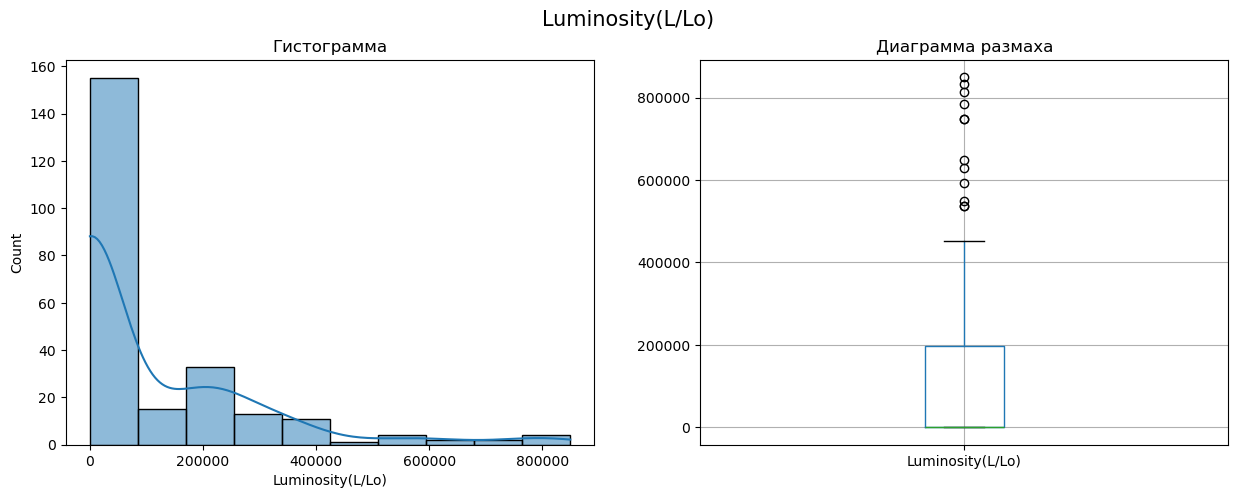

In [18]:
hist_and_boxplot('Luminosity(L/Lo)', df, 10)

Относительная светимость звезды относительно Солнца варьируется 0.00008 до 849420, т.е. есть звезды в сотни тысяч раз тусклее и в сотни тысяч раз ярче Солнца. Медианное значение - 0.0705, большая часть звезд тусклее Солнца.  	

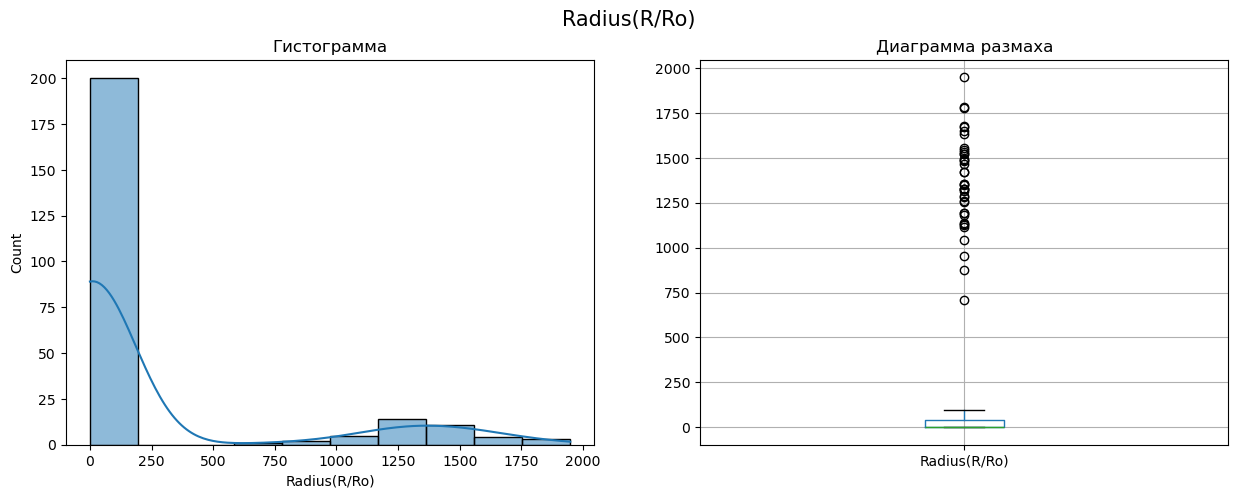

In [19]:
hist_and_boxplot('Radius(R/Ro)', df, 10)

Относительный радиус звезд варьируется 0.0084 до 1948.5, таким образом, также есть звезды в тысячи раз больше и тысячи раз меньше Солнца. Медианное значение - 0.7625, большая часть имеют радиус меньше, чем радиус Солнца. По гистограмме и диаграмме размаха видно, что нет звезд которые были больше Солнца в 200-500 раз, одна есть большое "скопление" звезд радиуся которых больше в 1000-1750 раз.  

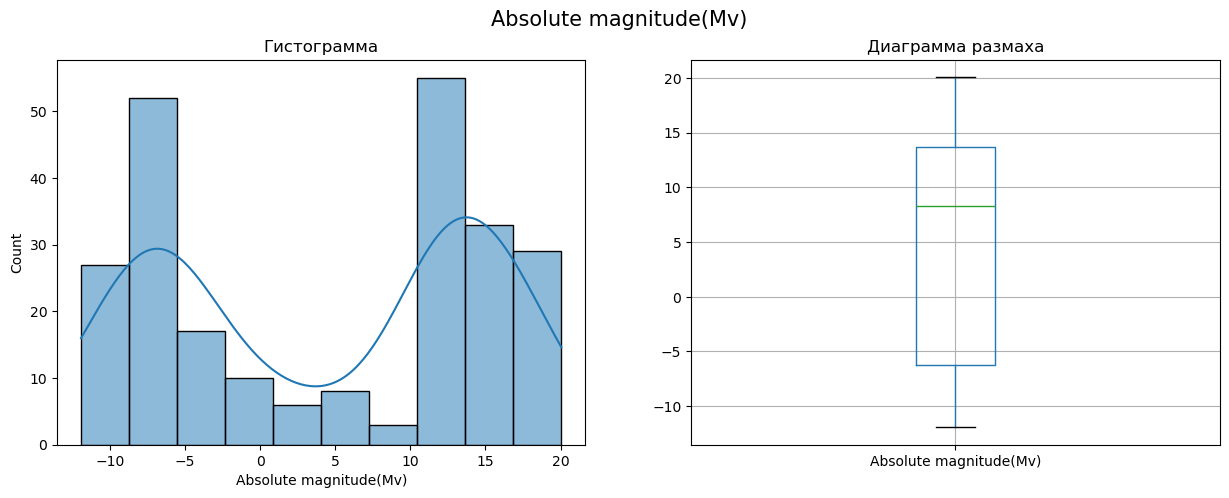

In [20]:
hist_and_boxplot('Absolute magnitude(Mv)', df, 10)

Абсолютная звездная величина варьируется от -11.92 до 20.06. На гистрограмме видны два пика, можно сказать, что есть большая часть звезд с отрицательной абсолютной звездной величиной около (-10:-5) и еще одна большая доля звезд с положительной звездной величиной около (10:20).  	

В столбце `Star type` хранится информация о типе звезды, это категориальные данные.

In [21]:
# Функция для построения столбчатой диаграммы для категориальных признаков
def count_plot(x, df):
    sns.countplot(
        x=x,
        data=df, 
        hue=x,
        palette='Set3',
        edgecolor='black',
        legend=False
    )
    plt.tight_layout() 
    plt.show()

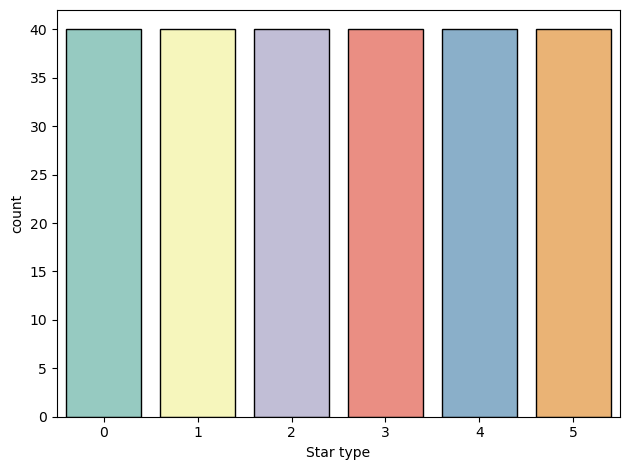

In [22]:
count_plot('Star type', df)

Среди 240 записей с характеристиками звезд встречаются всего 6 типов звезд. Количество звезд в каждом типе одинаково - по 40 штук.

In [23]:
# Функция для построения столбчатой диаграммы для категориальных признаков с сортировкой
def count_plot_sort(y, df):
    order = df[y].value_counts(ascending=False).index   # сортировка по убыванию
    sns.countplot(
        y=y,
        order=order,
        data=df, 
        hue=y,
        palette='Set3',
        edgecolor='black',
        legend=False
    )
    plt.tight_layout() 
    plt.show()

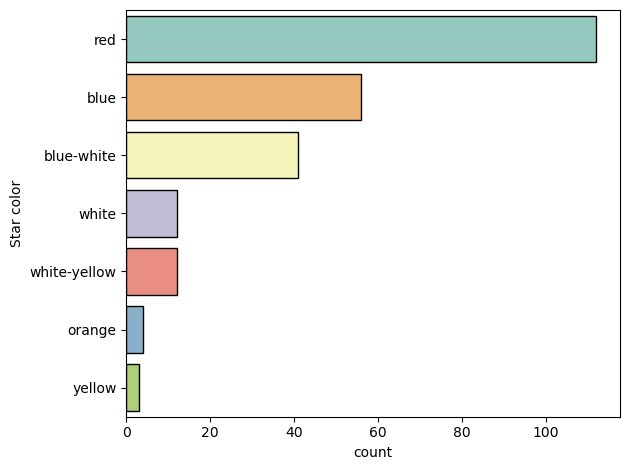

In [24]:
count_plot_sort('Star color', df)

После удаления неявных дубликатов осталось всего 11 цветов звезд, часть из них являются оттенками или смесью основных цветов. При этом большая часть красного цвета, значительное количество синего и белого-синего цвета. Звезд остальных цветов довольно малая часть.    

### Корреляционный анализ данных

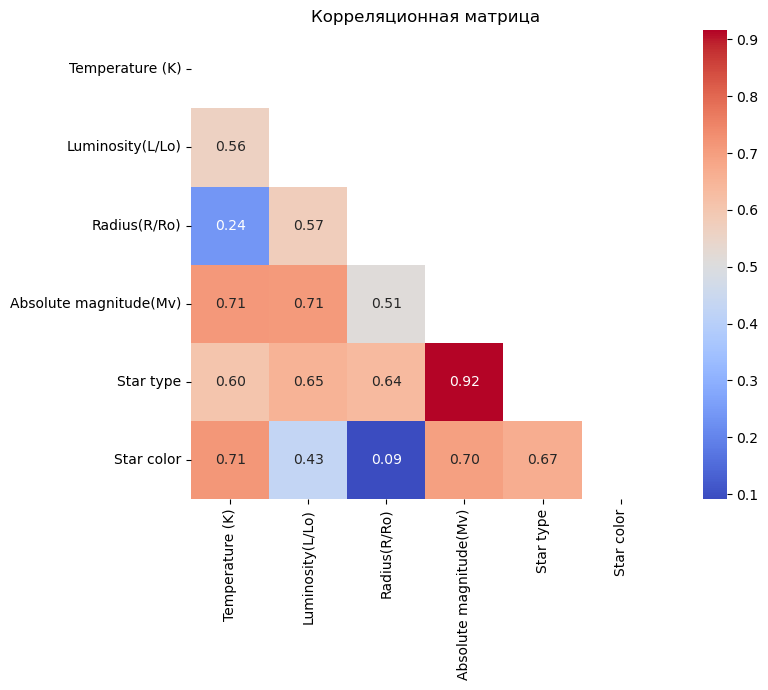

In [25]:
phik_matrix = df.phik_matrix(interval_cols=['Temperature (K)','Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)'])

mask = np.triu(np.ones_like(phik_matrix, dtype=bool))
plt.figure(figsize=(10, 7))
sns.heatmap(
    phik_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    mask=mask,
    square=True
)
plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()

У целевого признака (температура поверхности звезды) сильная положительная корреляция с абсолютной звездной величиной, которая характеризует блеск звезды, и цветом звезды. \
Из входных признаков наибольшая корреляция у абсолютной зведной величины и типом звезды, это логично т.к. тип звезды определяется по ее физическим характеристикам, в т.ч. и по ее блеску.

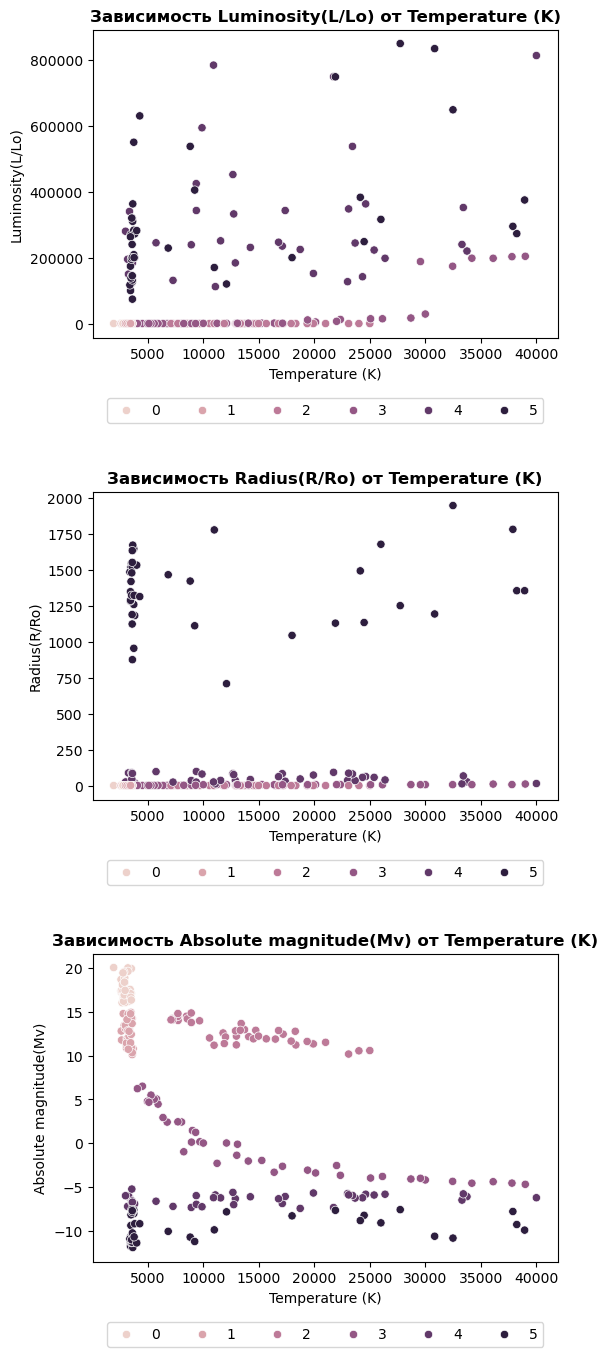

In [26]:
cols = ['Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)']

fig, axes = plt.subplots(3, 1, figsize=(6, 16))
    
fig.subplots_adjust(hspace=0.5, wspace=0.2)
    
for i, category in enumerate(cols):
    sns.scatterplot(
        data=df,
        x=df['Temperature (K)'],  # Используем параметр функции — имя колонки
        y=category,
        hue=df['Star type'],
        ax=axes[i]  # Используем i напрямую, т.к. axes одномерный
    )
        
    # Устанавливаем метки осей и подзаголовок
    axes[i].set_xlabel('Temperature (K)', fontsize=10)
    axes[i].set_ylabel(f'{category}', fontsize=10)
    axes[i].set_title(f'Зависимость {category} от Temperature (K)', fontsize=12, fontweight='bold')
    axes[i].legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), fancybox=True, ncol=6)
    
plt.show()

Звезды делятся на несколько типов: Коричневый карлик - 0, Красный карлик - 1, Белый карлик - 2, Звёзды главной последовательности - 3, Сверхгигант - 4, Гипергигант - 5. \
Видно, что определяющей характеристикой для определения типа звезды является ее абсолютная звездная величина, а также температура. 
* Абсолютная звездная величина у карликов положительная, больше 10 единиц.
* У звезд главной последовательности абсолютная звездная величина варьируется от -5 до 5.
* У гигантов абсолютная звездная величина отрицательная и меньше -5. А также большие размеры и светимости.
* Температура у Коричнего и красного карликов < 5000 K, а размеры и светимости меньше, чем у Солнца.
* Температуры белого карлика варьируется от порядка 10000 К до 25000 К.
* Температуры звезд главной последовательности и гигантов лежат во всех диапазоне температур. 

**Выводы по результатам предобработки и анализа данных**

1. Удален столбец, не несущий значимой информации для решения задачи.
2. Убедились в отсутствии пропусков и явных дубликатов, избавились от неявных дубликатов для колонки `Star color`.
3. Провели исследовательский и корреляционный анализы данных:
   * Почти у всех количественных признаков есть выбросы (температура, относительный радиус, относительная светимость), однако это обусловено физикой звёздных объектов, т.е. они отражают реальные астрономические явления.
   * Для категориального признака `Star type` распределение классов равномерное: представлено по 40 наблюдений каждого типа.
   * Для категориального признака `Star color` распределение равномерное: есть категории с 1-2 наблюдениями.
   * Есть сильно коррелирующие входные признаки, однако это ожидаемо с точки зрения астрофизики.

## Построение базовой нейронной сети

### Подготовка данных к построению модели

In [27]:
# Разделяем на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    df.drop('Temperature (K)', axis=1),
    df['Temperature (K)'],
    test_size=0.2,
    shuffle=True,
    random_state=42,
    stratify=df['Star color'] )

Категоризируем исходные данные, а также проведем масштабирование количественных данных.

In [28]:
print(f'Размерность обучающей выборки до обработки: {X_train.shape}')
print(f'Размерность тестовой выборки до обработки: {X_test.shape}')

Размерность обучающей выборки до обработки: (192, 5)
Размерность тестовой выборки до обработки: (48, 5)


In [29]:
scaler = StandardScaler()  # для преобразование числовых данных
ohe = OneHotEncoder()  # для преобразования категориальных данных

numerical_cols = ['Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)']
categorical_cols = ['Star type', 'Star color']

# Создаем трансформер для категориальных признаков
preprocessor = ColumnTransformer(
    transformers=[
         ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ])

# Обучаем пайплайн на обучающей выборке
X_train = preprocessor.fit_transform(X_train)

# Применяем к тестовой выборке 
X_test = preprocessor.transform(X_test)

In [30]:
print(f'Размерность обучающей выборки после обработки: {X_train.shape}')
print(f'Размерность тестовой выборки после обработки: {X_test.shape}')

Размерность обучающей выборки после обработки: (192, 14)
Размерность тестовой выборки после обработки: (48, 14)


### Построение базовой модели

In [31]:
# Создаем тензоры
X_train = torch.FloatTensor(np.array(X_train))
X_test = torch.FloatTensor(np.array(X_test))
y_train = torch.FloatTensor(np.array(y_train))
y_test = torch.FloatTensor(np.array(y_test))

Создадим класс для задания архитектуры нейронной сети. В качестве базы возьмем два скрытых слоя и ReLU в качестве функции активации для этих слоев, т.к. у нас задача регрессии.

In [32]:
class NeuralNet(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons, activation_fn=nn.ReLU):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.act1 = activation_fn()
        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.act2 = activation_fn()
        self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_neurons)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act1(x)
        x = self.fc2(x)
        x = self.act2(x)
        x = self.fc3(x)
        return x

Создадим функцию для обучения нейронной сети, которая будет искать лучший результат по RMSE для тестовой выборки. Выбор этой этой метрики качества обусловлен хорошей интерпретируемостью.

В качестве параметров будут: model, optimizer, а также обучающие и тестовые выборки.

In [33]:
def neural_net(model, optimizer, X_train, y_train, X_test, y_test):
    num_epochs = 5000
    loss_fn = nn.MSELoss()

    best_rmse = float('inf')
    best_epoch = 0
    best_predictions = None
    best_model_state = None

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()

        preds = model(X_train).flatten()
        mse_loss = loss_fn(preds, y_train)
        rmse_loss = torch.sqrt(mse_loss)

        mse_loss.backward()
        optimizer.step()

        if epoch % 50 == 0:
            model.eval()
            with torch.no_grad():
                test_preds = model(X_test).flatten()
                test_mse = loss_fn(test_preds, y_test)
                test_rmse = torch.sqrt(test_mse)

            current_rmse = test_rmse.item()
            if current_rmse < best_rmse:
                best_rmse = current_rmse
                best_epoch = epoch
                best_predictions = test_preds.clone().detach()
                best_model_state = model.state_dict()  # Сохраняем лучшую модель

    # Загружаем лучшие веса
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return best_rmse, best_epoch, model

Количество нейронов на выходном и выходном слоях будет фиксированно:
* n_in_neurons = X_train.shape[1]
* n_out_neurons = 1
  
Количество нейронов на скрытых слоях можно варьировать. Также можно проверить разные функции активации. Для задач регрессии можно использовать ReLU или ее модификации - ELU и LeakyReLU. Проверим несколько комбинаций и обучим модели.

In [34]:
# Список конфигураций скрытых слоев для перебора
hidden_configs = [
    [8, 4],
    [10, 6],
    [12, 8]
]

# Список функций активации для перебора
activation_functions = [
    nn.ReLU,
    nn.ELU,
    nn.LeakyReLU
]

In [35]:
best_rmse = float('inf')
best_config = None
best_activation = None
best_model = None
results = {}

for hidden_sizes in hidden_configs:
    for activation_fn in activation_functions:
        n_hidden_1, n_hidden_2 = hidden_sizes

        # Создаем модель с текущей активацией
        model = NeuralNet(
            n_in_neurons=X_train.shape[1],
            n_hidden_neurons_1=n_hidden_1,
            n_hidden_neurons_2=n_hidden_2,
            n_out_neurons=1,
            activation_fn=activation_fn
        )

        optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

        # Обучаем модель
        rmse, epoch, trained_model = neural_net(
            model, optimizer, X_train, y_train, X_test, y_test
        )

        activation_name = activation_fn.__name__ if hasattr(activation_fn, '__name__') else str(activation_fn)
        results[f"{hidden_sizes}_{activation_name}"] = {'rmse': rmse, 'epoch': epoch}

        print(f'{str(hidden_sizes):<15} {activation_name:<12} {rmse:<10.2f} {epoch:<8}')

        # Сохраняем лучший результат
        if rmse < best_rmse:
            best_rmse = rmse
            best_config = hidden_sizes
            best_activation = activation_name
            best_model = trained_model

print(f'\nЛУЧШИЙ РЕЗУЛЬТАТ: Скрытые слои {best_config}, Функция активации {best_activation}, RMSE = {best_rmse:.2f}')

[8, 4]          ReLU         4742.71    2750    
[8, 4]          ELU          3772.37    4950    
[8, 4]          LeakyReLU    4395.07    4950    
[10, 6]         ReLU         4704.10    2000    
[10, 6]         ELU          4227.22    1400    
[10, 6]         LeakyReLU    4578.65    1550    
[12, 8]         ReLU         4370.24    4900    
[12, 8]         ELU          4097.63    1600    
[12, 8]         LeakyReLU    4479.20    4950    

ЛУЧШИЙ РЕЗУЛЬТАТ: Скрытые слои [8, 4], Функция активации ELU, RMSE = 3772.37


Видно, что выбор функции активации существенно влияет на качество модели: модификации ReLU демонстрируют сильное улучшение RMSE. Необходимый результат (RMSE < 4500) достигается либо с функцией активации ELU, либо с функцией активации LeakyReLU при любом количестве нейронов на скрытых слоях. ReLU дает приемлимый результат только при конфигурации с наибольшим количествов нейронов.

### График «Факт — Прогноз»

Создадим функцию для визуализации качества, где по горизонтальной оси будут отложены условные номера звёзд, а по вертикальной — температура в Кельвинах.

In [36]:
def fact_prediction(test_preds, y_test, title='model'):
    
    y1 = torch.FloatTensor(test_preds)
    y1 = y1.detach().numpy().reshape([-1])
    y2 = y_test.detach().numpy().reshape([-1])
    x = np.arange(len(y1))

    fig, ax = plt.subplots(figsize=(15, 8))
    fact = ax.bar(x, y2, width=0.6, color='skyblue', label = 'Факт')
    prediction = ax.bar(x, y1, width=0.3, color='gold', label = 'Прогноз')
    
    ax.set_xticks(x)
    ax.set_xlabel('Номер звезды в таблице данных')
    ax.set_ylabel('Температура звезды')
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), fancybox=True, ncol=2)
    ax.grid(True, alpha=0.1)
    plt.show()

Построим график для модели с лучшей метрикой качества из полученных. 

In [37]:
best_model.eval()  # режим вывода
with torch.no_grad():
    baseline_predictions = best_model(X_test).flatten()

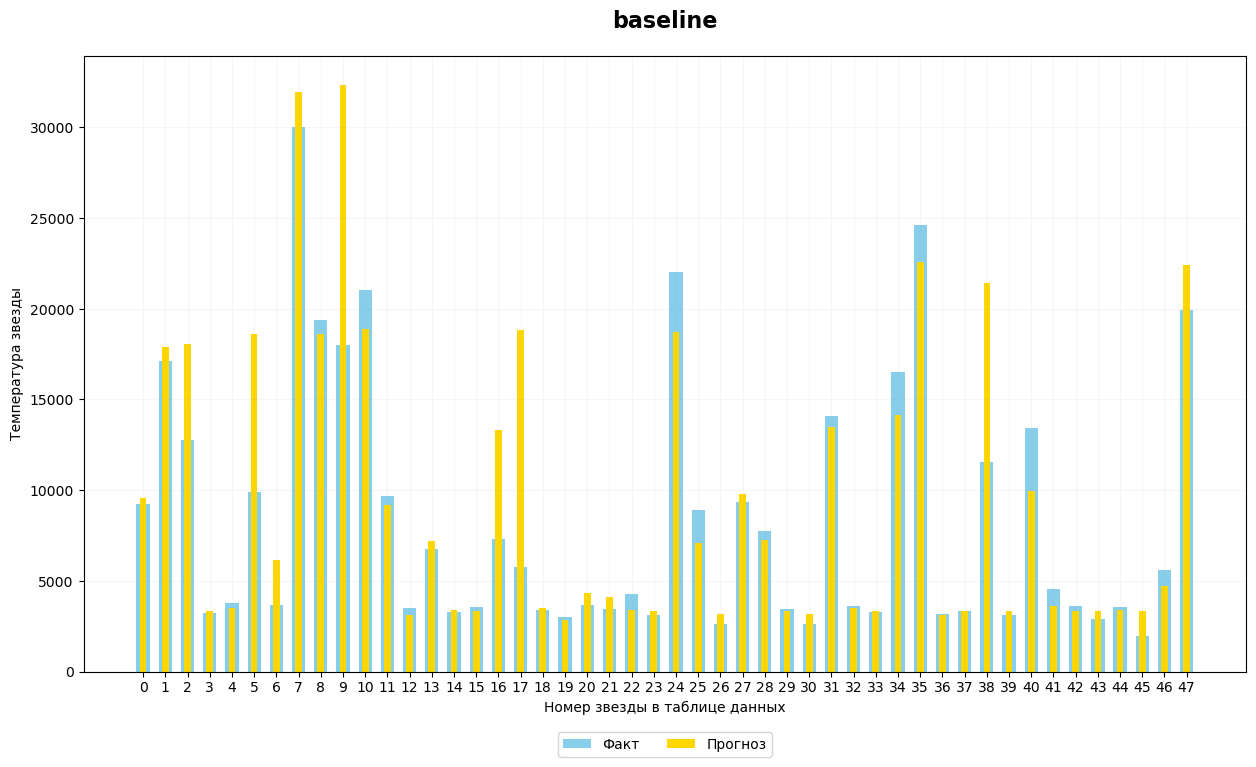

In [38]:
# Построим график
fact_prediction(baseline_predictions, y_test, 'baseline')

**Выводы**

Анализ графика показывает, что модель демонстрирует довольно высокую точность прогнозирования температуры поверхности звезд в диапазоне до 5 тысяч К. Для звезд с температурой свыше 10 тысяч К наблюдается значительное расхождение между прогнозом и фактическими значениями. Это, вероятно, обусловлено недостаточным количеством таких звезд в обучающей выборке.

## Улучшение нейронной сети

Попробуем улучшить метрику качества с помощью перебора размера батча и регуляризации базовой нейросети, используя Batch Normalization и Dropout. Количество слоёв оставим как в baselinе, количество нейронов на скрытых слоях -  8 и 4 и в качестве функции активации возьмем ELU, показавшей лучший результат. 

### Batch Normalization

Создадим новый класс для задания архитектуры нейронной сети с использованием Batch Normalization. 

In [39]:
class NetWithBN(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons):
        super(NetWithBN, self).__init__()

        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.bn1 = nn.BatchNorm1d(n_hidden_neurons_1)    # добавляем BN
        self.act1 = nn.ELU()

        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.bn2 = nn.BatchNorm1d(n_hidden_neurons_2)   # добавляем BN
        self.act2 = nn.ELU()

        self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_neurons)

    def forward(self, x):
        x = self.fc1(x)
        x = self.bn1(x)   # используем BN
        x = self.act1(x)

        x = self.fc2(x)
        x = self.bn2(x)   # используем BN
        x = self.act2(x)

        x = self.fc3(x)  
        return x

In [40]:
model = NetWithBN(
    n_in_neurons=X_train.shape[1],
    n_hidden_neurons_1=8,
    n_hidden_neurons_2=4,
    n_out_neurons=1
)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

# Обучаем модель
best_rmse_BN, best_epoch_BN, model_BN = neural_net(
    model, optimizer, X_train, y_train, X_test, y_test
)

# Выводим результаты
print(f'RMSE = {best_rmse_BN:.2f}, epoch {best_epoch_BN}')

RMSE = 5416.23, epoch 4850


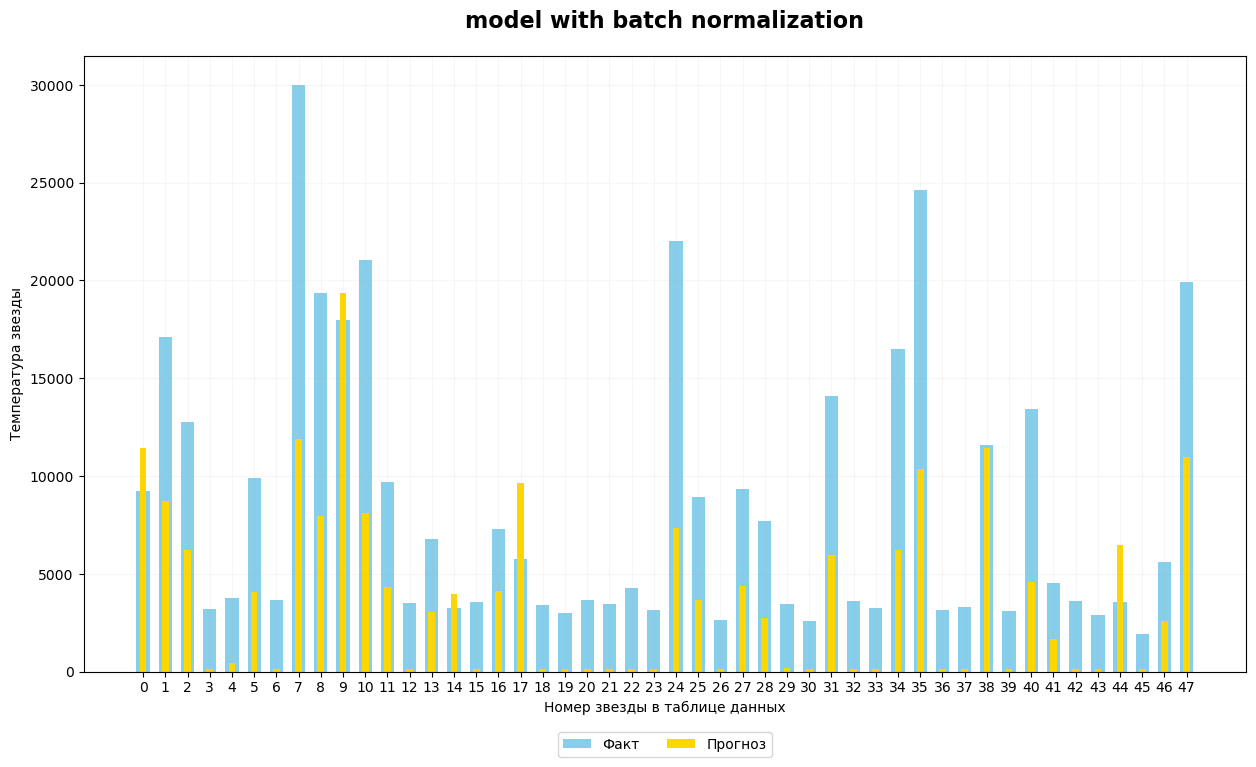

In [41]:
model_BN.eval()  # режим вывода
with torch.no_grad():
    model_BN_predictions = model_BN(X_test).flatten()

# Построим график
fact_prediction(model_BN_predictions, y_test, 'model with batch normalization')

Использование Batch Normalization не дало улучшения RSME: модель стала плохо предсказывать и для объектов с поверхностной температурой < 5 тысяч К.

### Dropout + batch size

Создадим новый класс для задания архитектуры нейронной сети с использованием Dropout. 

In [42]:
class NetWithDropout(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons, p=0.1):
        super(NetWithDropout, self).__init__()
        
        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.act1 = nn.ELU()
        self.dropout1 = nn.Dropout(p)   # добавляем Dropout
        
        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.act2 = nn.ELU()
        self.dropout2 = nn.Dropout(p)   # добавляем Dropout
        
        self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_neurons)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.act1(x)
        x = self.dropout1(x)   # используем dropout
        
        x = self.fc2(x)
        x = self.act2(x)
        x = self.dropout2(x)   # используем dropout
        
        x = self.fc3(x) 
        return x

Создадим функцию для обучения нейронной сети c заданным размером батча.

In [43]:
def neural_net_with_batch_size(model, optimizer, X_train, y_train, X_test, y_test, batch_size):
    num_epochs = 5000
    loss_fn = nn.MSELoss()

    best_rmse = float('inf')
    best_epoch = 0
    best_predictions = None
    best_model_state = None

    # Создаем DataLoader с текущим batch_size
    dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    for epoch in range(num_epochs):
        model.train()

        # Обучение по батчам
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            preds = model(batch_X).flatten()
            mse_loss = loss_fn(preds, batch_y)
            mse_loss.backward()
            optimizer.step()

        # Валидация каждые 50 эпох
        if epoch % 50 == 0:
            model.eval()
            with torch.no_grad():
                test_preds = model(X_test).flatten()
                test_mse = loss_fn(test_preds, y_test)
                test_rmse = torch.sqrt(test_mse)

            current_rmse = test_rmse.item()
            if current_rmse < best_rmse:
                best_rmse = current_rmse
                best_epoch = epoch
                best_predictions = test_preds.clone().detach()
                best_model_state = model.state_dict()

    # Загружаем лучшие веса
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return best_rmse, best_epoch, model

In [44]:
# Список размеров батча для перебора
batch_sizes = [4, 8, 16, 32]
# Список dropout для перебора
dropouts = [0.1, 0.2, 0.3, 0.5]

results = []

# Перебираем все комбинации batch_size и dropout
for batch_size, p in itertools.product(batch_sizes, dropouts):
    print(f'batch_size = {batch_size}, dropout = {p}')
    
    # Создаём новую модель с текущим dropout
    model = NetWithDropout(
        n_in_neurons=X_train.shape[1],
        n_hidden_neurons_1=8,
        n_hidden_neurons_2=4,
        n_out_neurons=1,
        p=p
    )
    
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
    
    # Обучаем модель с текущим размером батча
    best_rmse_dropout, best_epoch_dropout, model_dropout = neural_net_with_batch_size(
        model, optimizer, X_train, y_train, X_test, y_test, batch_size
    )
    
    # Сохраняем результаты
    results.append({
        'batch_size': batch_size,
        'dropout': p,
        'best_rmse_dropout': best_rmse_dropout,
        'best_epoch_dropout': best_epoch_dropout,
        'model_dropout': model_dropout
    })
    
    print(f'RMSE = {best_rmse_dropout:.2f}, epoch {best_epoch_dropout}')

# Находим лучшую комбинацию параметров
best_result = min(results, key=lambda x: x['best_rmse_dropout'])
print(f'\nЛУЧШИЙ РЕЗУЛЬТАТ:')
print(f'Batch size: {best_result['batch_size']}')
print(f'Dropout: {best_result['dropout']}')
print(f'RMSE = {best_result['best_rmse_dropout']:.2f}')

batch_size = 4, dropout = 0.1
RMSE = 3870.96, epoch 1100
batch_size = 4, dropout = 0.2
RMSE = 3800.34, epoch 3150
batch_size = 4, dropout = 0.3
RMSE = 3750.34, epoch 400
batch_size = 4, dropout = 0.5
RMSE = 3913.54, epoch 4450
batch_size = 8, dropout = 0.1
RMSE = 3937.20, epoch 650
batch_size = 8, dropout = 0.2
RMSE = 3905.31, epoch 800
batch_size = 8, dropout = 0.3
RMSE = 3936.71, epoch 1850
batch_size = 8, dropout = 0.5
RMSE = 4670.60, epoch 4200
batch_size = 16, dropout = 0.1
RMSE = 3934.96, epoch 2000
batch_size = 16, dropout = 0.2
RMSE = 3987.23, epoch 1300
batch_size = 16, dropout = 0.3
RMSE = 3890.81, epoch 4450
batch_size = 16, dropout = 0.5
RMSE = 3929.91, epoch 4750
batch_size = 32, dropout = 0.1
RMSE = 4059.53, epoch 1400
batch_size = 32, dropout = 0.2
RMSE = 9838.88, epoch 4950
batch_size = 32, dropout = 0.3
RMSE = 3808.44, epoch 2550
batch_size = 32, dropout = 0.5
RMSE = 4485.10, epoch 4850

ЛУЧШИЙ РЕЗУЛЬТАТ:
Batch size: 4
Dropout: 0.3
RMSE = 3750.34


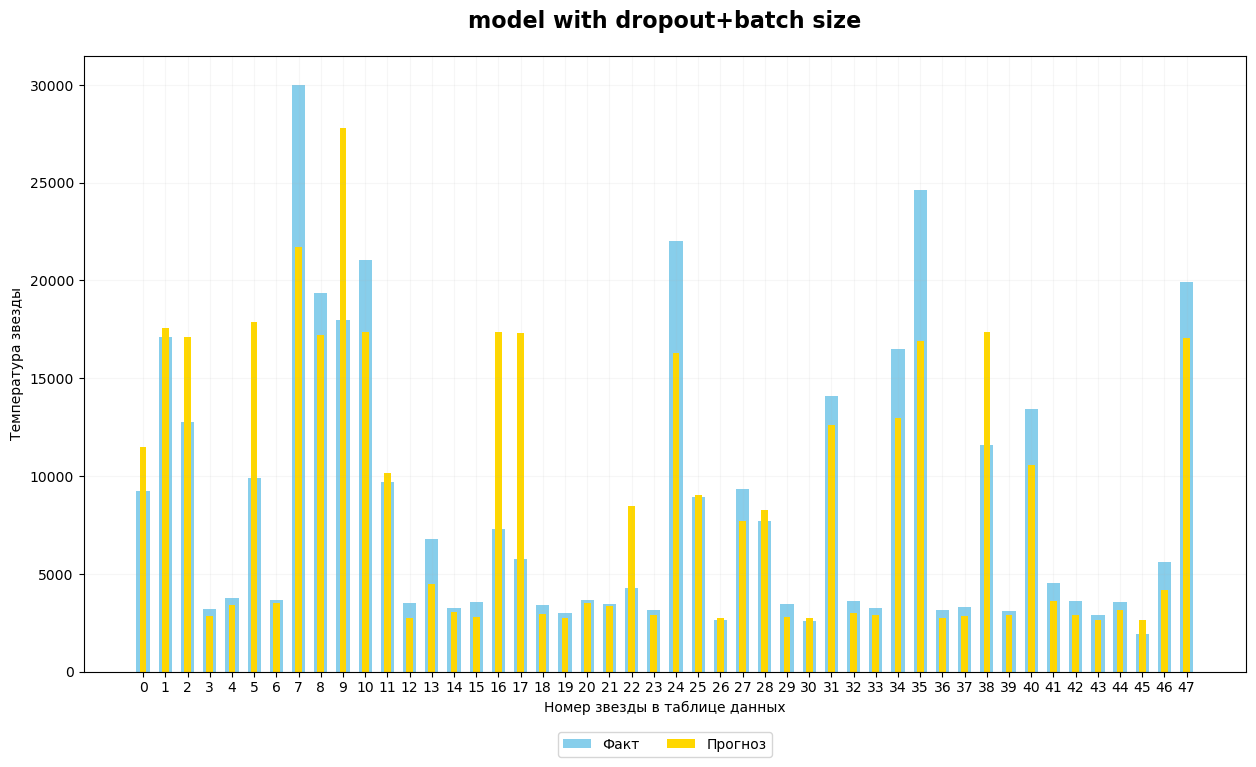

In [45]:
best_model = best_result['model_dropout']
best_model.eval()  # режим вывода

with torch.no_grad():
    dropout_predictions = best_model(X_test).flatten()

# Построим график
fact_prediction(dropout_predictions, y_test, 'model with dropout+batch size')

Совместное использование Dropout и перебора Batch size немного улучшило RSME.

**Выводы**

In [46]:
print("Таблица результатов:")
print("-" * 45)
print(f"{'Модель':<35} {'RMSE':<10}")
print("-" * 45)

print(f"{'Baseline':<35} {best_rmse:<10.2f}")
print(f"{'With Batch Normalization':<35} {best_rmse_BN:<10.2f}")
print(f"{'With Dropout+Batch Size ':<35} {best_result['best_rmse_dropout']:.2f}")

Таблица результатов:
---------------------------------------------
Модель                              RMSE      
---------------------------------------------
Baseline                            3772.37   
With Batch Normalization            5416.23   
With Dropout+Batch Size             3750.34


Базовая модель нейронной сети показала хорошую метрику качества (RMSE). Такой результат был достигнут за счет перебора количества нейронов на скрытых слоях и подбора лучшей функции активации. \
При использовании Batch Normalization RMSE значительно возросло. Однако дальнейший перебор параметров нейросети - совместный перебор параметра p Dropout и Batch size все-таки улучшил исходную метрику качества.

## Выводы

Были выполнены следующие этапы работы:

**1. Загрузка данных** 

Загружены данные c информацией о характеристиках изученных звезд. Объем данных ограничен (240 объектов).   

**2. Предобработка и анализ данных**

На этапе предобработки выполнена проверка на пропуски и явные дубликаты, избавились от неявных дубликатов для колонки `Star color`.

Выполнены исследовательский и корреляционный анализ данных: выявлены корреляции между признаками и целевой переменной.

**3. Построение базовой нейронной сети**

Выполнено кодирование категориальных и масштабирование числовых признаков

Создана и обучена базовая модель нейронной сети (baseline) со следующей архитектурой:

* входной слой (размер соответствует числу признаков после кодирования);
* 2 скрытых слоя;
* выходной слой (1 нейрон);
  
Используется оптимизатор Adam (из-за его скорости). Метрика качества: RMSE.

Количество нейронов и функции активации в скрытых слоях подобраны экспериментально. Лучший результат показала модель с функцией активации ELU, став опорной точкой для дальнейших улучшений.

**4. Улучшение нейронной сети**

Проведены эксперименты по улучшению базовой модели:

* применение Batch Normalization;
* применение Dropout и настройка размера батча(с разными коэффициентами).
  
Применение Batch Normalization не привело к улучшению RMSE. А вот совместное применение Dropout и настройка размера батча улучшили метрику качества, но не очень сильно. Вероятно, из-за ограниченного объема данных - для дальнейшего улучшения качества требуется расширение датасета. 

Основная цель работы достигнута: была разработана и обучена нейронная сеть для прогнозирования температуры поверхности звезд по наблюдаемым характеристикам. Модель способна давать оценки температуры с приемлемой точностью.

Полученные результаты могут быть использованы обсерваторией для предварительной оценки температуры новых обнаруженных звезд до проведения спектрального анализа и других более трудоемких расчетов.